In [1]:
from langgraph.graph import StateGraph, START,END ,MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages.utils import trim_messages,count_tokens_approximately,RemoveMessage



load_dotenv()
llm =  ChatOpenAI(model="gpt-4o-mini")


In [2]:
class Chat(MessagesState):
    
    summary :  str 
    

def chat_node(state : Chat):
    
    messages = []
    
    if state["summary"]:
        messages.append({"role":"assistant","messages":state['summary']})
    messages.extend(state["messages"])
    
    ans =  llm.invoke(messages)
    
    return {"messages":ans}



def should_summarize(state : Chat):
    
    return len(state['messages']) >  6

def summarize_the_convo(state: Chat):
    
    # task 1 : summarize all inlcuding new summary and messages 
    # task 2 : keep only last 2 messaages and trim or delete rest 
    
    if state["summary"] : 
        new_summary_prompt = f" Old summary is {state['summary']} and new messages are {state['messages']} now summarize all of this "
        
    else:
        new_summary_prompt =  f"summarize this convo {state['messages']}"
        
    new_summary =  llm.invoke(new_summary_prompt).content 
    
    new_messages =  [ RemoveMessage(id=m.id) for m in state['messages'][:-2] ]# till last 2 
    
    
    return {"summary":new_summary,"messages":new_messages}
    
    
    
        
    
    

In [3]:
graph  = StateGraph(Chat)
graph.add_node("chat_node",chat_node)
graph.add_node("summarize",summarize_the_convo)



graph.add_edge(START,"chat_node")
graph.add_conditional_edges("chat_node",should_summarize,{
    True  : "summarize",
    False :  END 
})

graph.add_edge("summarize",END)


checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

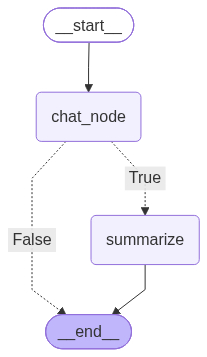

In [4]:

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [6]:
config = {"configurable": {"thread_id": "chat1"}}

def run_turn(text: str):
    out = workflow.invoke({"messages": [{"role":"user","content":text}], "summary": ""}, config=config)
    return out

def show_state():
    
    snaps =  workflow.get_state(config=config)
    print("Length of snaps : ",len(snaps.values.get("messages", [])))
    print("summary:" , snaps.values["summary"])
    
    print("-- messages --")
    for idx,i in enumerate(snaps.values['messages']):
        print(f"{idx+1}) {i.content}")

In [7]:
run_turn("How is albert enstien ? ")
show_state()

Length of snaps :  2
summary: 
-- messages --
1) How is albert enstien ? 
2) Albert Einstein was a renowned theoretical physicist best known for developing the theory of relativity, particularly the equation \(E=mc^2\), which describes the equivalence of mass and energy. Born on March 14, 1879, in Ulm, Germany, and passing away on April 18, 1955, in Princeton, New Jersey, his work has had a profound impact on our understanding of physics and the universe.

Einstein made significant contributions to the field of physics, including the understanding of the photoelectric effect, for which he received the Nobel Prize in Physics in 1921. He also contributed to the development of quantum mechanics and cosmology.

Aside from his scientific work, Einstein was known for his philosophical views on science, politics, and human rights. He was a pacifist, a supporter of civil rights, and a vocal opponent of nationalism and militarism.

If you meant to ask something else or had a specific aspect of 

In [8]:
run_turn(" tell me a little about solar system ? ")
show_state()

Length of snaps :  4
summary: 
-- messages --
1) How is albert enstien ? 
2) Albert Einstein was a renowned theoretical physicist best known for developing the theory of relativity, particularly the equation \(E=mc^2\), which describes the equivalence of mass and energy. Born on March 14, 1879, in Ulm, Germany, and passing away on April 18, 1955, in Princeton, New Jersey, his work has had a profound impact on our understanding of physics and the universe.

Einstein made significant contributions to the field of physics, including the understanding of the photoelectric effect, for which he received the Nobel Prize in Physics in 1921. He also contributed to the development of quantum mechanics and cosmology.

Aside from his scientific work, Einstein was known for his philosophical views on science, politics, and human rights. He was a pacifist, a supporter of civil rights, and a vocal opponent of nationalism and militarism.

If you meant to ask something else or had a specific aspect of 